# Símbolos manuscritos → LaTeX: entrenamiento y resultados

**PC2 de Computación Gráfica — UNI.** Clasificación de seis símbolos aislados: α, ξ, ∞, ≡, ∂ y ∈, con la CNN de PyTorch del repositorio y su aplicación Flask.

Esta versión utiliza exclusivamente los **3,167 dibujos propios del equipo**: entrenamiento P01 y P03 (1,661), validación P04 (750) y prueba P02 (756). Recupera el entrenamiento existente en `models/symbols`, verifica sus evidencias y vuelve a evaluar el checkpoint; **no reentrena ni sobrescribe pesos o datos**. Los campos históricos `hasy_symbol_id` del catálogo no implican uso de HASYv2.

## Ejecutar en Google Colab o con VS Code

En Colab, ejecuta en orden. Si el repositorio no está disponible, la primera celda solicita el ZIP del proyecto: debe incluir `src/`, `config/`, `main.py`, `data/processed/`, `data/raw/` y `models/symbols/`. Se extrae una copia temporal sin reutilizar los entornos Windows `.venv`. También puedes definir la variable de entorno `PC2_ROOT` con la ruta al proyecto ya disponible. No basta con subir únicamente este notebook.

En VS Code, selecciona el kernel del entorno con las dependencias de `requirements*.txt`. La celda inicial instala solamente dependencias ausentes; informa las versiones utilizadas. El entrenamiento original registró PyTorch **2.7.1+cpu**; para una réplica estricta instala los requisitos versionados del repositorio en un entorno separado.

**Alcance de la comprobación:** las salidas guardadas en esta copia proceden de una ejecución real en ChatGPT Work (CPU), no de un runtime de Google Colab. El historial se recupera del entrenamiento original; esta sesión no vuelve a ejecutar sus 29 épocas. El notebook mantiene las 18 celdas y el orden de secciones del original. No se reutilizan sus salidas obsoletas de HASY.


In [9]:
from pathlib import Path
import os, sys, json, platform, hashlib, tempfile, zipfile
import importlib.util, subprocess
from datetime import datetime, timezone

# Localización explícita, ancestros y dos niveles bajo el directorio actual.
def find_root():
    candidates = ([Path(os.environ['PC2_ROOT'])] if os.environ.get('PC2_ROOT') else [])
    candidates += [Path.cwd(), *Path.cwd().parents]
    candidates += [p.parent.parent for pattern in ('*/config/symbols.json', '*/*/config/symbols.json')
                   for p in Path.cwd().glob(pattern)]
    return next((p.resolve() for p in candidates
                 if (p/'config/symbols.json').is_file() and (p/'src/model.py').is_file()), None)

ROOT = find_root()
if ROOT is None:
    if importlib.util.find_spec('google.colab') is not None:
        from google.colab import files
        print('Sube el ZIP del proyecto completo; no se modificará el archivo original.')
        uploaded = files.upload()
        archives = [Path(name) for name in uploaded if name.lower().endswith('.zip')]
        if len(archives) != 1:
            raise RuntimeError('Selecciona exactamente un ZIP del proyecto completo.')
        extracted = Path(tempfile.mkdtemp(prefix='pc2-colab-'))
        with zipfile.ZipFile(archives[0]) as archive:
            for member in archive.infolist():
                relative = Path(member.filename)
                if relative.is_absolute() or '..' in relative.parts:
                    raise ValueError('Ruta insegura en el ZIP.')
                if any(part.startswith('.venv') or part in ('.git', '__pycache__') for part in relative.parts):
                    continue
                archive.extract(member, extracted)
        roots = [p.parent.parent for p in extracted.rglob('config/symbols.json')
                 if (p.parent.parent/'src/model.py').is_file()]
        if len(roots) != 1:
            raise RuntimeError('El ZIP debe contener un único proyecto con config/symbols.json y src/model.py.')
        ROOT = roots[0].resolve()
    else:
        raise RuntimeError('Extrae el ZIP y define PC2_ROOT con la raíz que contiene src/ y config/.')

# Colab suele incluir PyTorch; no se sustituye una instalación disponible.
packages = {'numpy':'numpy==2.2.6', 'PIL':'pillow==12.0.0',
            'matplotlib':'matplotlib==3.10.8', 'flask':'Flask==3.1.3'}
for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch==2.7.1+cpu',
                           '--index-url', 'https://download.pytorch.org/whl/cpu'])
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
import numpy as np
import torch
from IPython.display import display, Markdown, Image as NotebookImage
from src.training_data import load_dataset, split_dataset, PREPROCESSING, catalog_signature
from src.model import SymbolCNN
from src.evaluation import classification_metrics
from src.training import evaluate

def protected_hashes():
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
            for directory in ('data', 'models') for p in (ROOT/directory).rglob('*') if p.is_file()}
PROTECTED_BEFORE = protected_hashes()
print('Raíz:', ROOT)
print('Validación:', datetime.now(timezone.utc).isoformat(), 'Python:', platform.python_version())
print('NumPy:', np.__version__, 'PyTorch:', torch.__version__, 'Dispositivo de validación: CPU')
print('Archivos de datos/modelos protegidos:', len(PROTECTED_BEFORE))


Raíz: C:\Users\Cristian Diaz\Desktop\PC2Grafica\PC2_clasificacionImg_CompuGrafica
Validación: 2026-10-16T15:39:39.288529+00:00 Python: 3.12.10
NumPy: 2.2.6 PyTorch: 2.7.1+cpu Dispositivo de validación: CPU
Archivos de datos/modelos protegidos: 6376


## 1. Configuración del experimento

El único origen admitido es la colección propia. Se lee el experimento auténtico `models/symbols`; la celda no invoca `train_model`. Se mantienen semilla 42, máximo de 30 épocas, batch size 32 y paciencia 7 documentados en sus metadatos. Una nueva ejecución de evaluación no equivale a un nuevo entrenamiento.


In [10]:
SOURCE = 'own'
SEED, EPOCHS, BATCH_SIZE, PATIENCE = 42, 30, 32, 7
DATA = ROOT / 'data' / 'processed'
OUTPUT = ROOT / 'models' / 'symbols'
EXPECTED_GROUPS = {'train': {'P01', 'P03'}, 'validation': {'P04'}, 'test': {'P02'}}
EXPECTED_COUNTS = {'train': 1661, 'validation': 750, 'test': 756}
required = ['model.pt', 'model_info.json', 'metrics.json', 'history.json', 'split.json', 'test_predictions.csv']
missing = [str(OUTPUT/name) for name in required if not (OUTPUT/name).is_file()]
if missing:
    raise FileNotFoundError('Faltan evidencias originales; no se entrenará un reemplazo: ' + ', '.join(missing))
info = json.loads((OUTPUT/'model_info.json').read_text(encoding='utf-8'))
metrics_saved = json.loads((OUTPUT/'metrics.json').read_text(encoding='utf-8'))
history = json.loads((OUTPUT/'history.json').read_text(encoding='utf-8'))
split_saved = json.loads((OUTPUT/'split.json').read_text(encoding='utf-8'))
assert info['source_type'] == 'app_collection' and info['purpose'] == 'collected_dataset'
assert (info['seed'], info['epochs_requested'], info['batch_size'], info['patience']) == (SEED, EPOCHS, BATCH_SIZE, PATIENCE)
print('Origen:', SOURCE, '| Experimento recuperado:', OUTPUT.name, '| Reentrenamiento: desactivado')


Origen: own | Experimento recuperado: symbols | Reentrenamiento: desactivado


## 2. Preparar y revisar los datos

Se leen los arrays y el manifiesto originales con `src.training_data.load_dataset`, sin regenerarlos. Se valida la alineación entre etiquetas, códigos de participante y muestras, el rango de píxeles, los identificadores y hashes únicos del manifiesto y la huella SHA-256 del conjunto usado para entrenar.

El preprocesamiento real de `src/preprocessing.py` compone transparencias sobre blanco, convierte a gris, invierte la intensidad, localiza tinta con umbral >20 y exige al menos ocho píxeles de tinta. Recorta la caja de contenido, conserva la proporción al ajustar a **24×24 como máximo** y centra en un lienzo **32×32**, con margen mínimo de cuatro píxeles. Produce `float32`, fondo 0, tinta alta y rango [0,1]. Para PyTorch se transforma NHWC → NCHW. No se aplica de nuevo el recorte a los arrays ya procesados.

Se comprueban además todos los PNG originales contra su hash y contra la salida real de `preprocess_image`; esto valida la correspondencia del repositorio con los arrays, sin modificar datos.


In [11]:
from PIL import Image
from src.preprocessing import preprocess_image

dataset = load_dataset(DATA)
assert dataset.source_type == 'app_collection'
assert len(dataset.y) == info['n_samples'] == 3167
assert dataset.fingerprint == info['dataset_sha256'], 'El dataset no corresponde al entrenamiento guardado.'
assert set(dataset.participants) == {'P01', 'P02', 'P03', 'P04'}
assert dataset.excluded_demo == 0
assert np.bincount(dataset.y, minlength=6).tolist() == info['class_counts']
raw_directory = DATA.parent/'raw'
max_pixel_difference = 0.0
for i, record in enumerate(dataset.records):
    png_path = (raw_directory/record['path']).resolve()
    assert png_path.is_relative_to(raw_directory.resolve())
    assert hashlib.sha256(png_path.read_bytes()).hexdigest() == record['image_sha256']
    with Image.open(png_path) as image:
        processed = preprocess_image(image)
    difference = float(np.max(np.abs(processed-dataset.X[i])))
    max_pixel_difference = max(max_pixel_difference, difference)
assert max_pixel_difference <= 1/255 + 1e-7, 'Discrepancia entre preprocesamiento actual y exportación.'
print('Origen:', dataset.source_description)
print('X:', dataset.X.shape, dataset.X.dtype, '| y:', dataset.y.shape)
print('Huella SHA-256:', dataset.fingerprint)
print('PNG revisados:', len(dataset.records), '| Mayor diferencia absoluta de píxel:', max_pixel_difference)
counts = np.bincount(dataset.y, minlength=6)
table = '| Clase | Símbolo | LaTeX | Muestras |\n|---|:---:|---|---:|\n'
for symbol, count in zip(dataset.catalog['symbols'], counts):
    table += f"| {symbol['id']} | {symbol['unicode']} | `{symbol['latex']}` | {count} |\n"
display(Markdown(table))


Origen: dibujos recolectados en la aplicacion
X: (3167, 32, 32, 1) float32 | y: (3167,)
Huella SHA-256: 47403ac9b076453f2969d02699492bec240cee0a0c72a15a859e7130c0c1f263
PNG revisados: 3167 | Mayor diferencia absoluta de píxel: 0.0


| Clase | Símbolo | LaTeX | Muestras |
|---|:---:|---|---:|
| alpha | α | `\alpha` | 528 |
| xi | ξ | `\xi` | 527 |
| infty | ∞ | `\infty` | 528 |
| equiv | ≡ | `\equiv` | 528 |
| partial | ∂ | `\partial` | 528 |
| in | ∈ | `\in` | 528 |


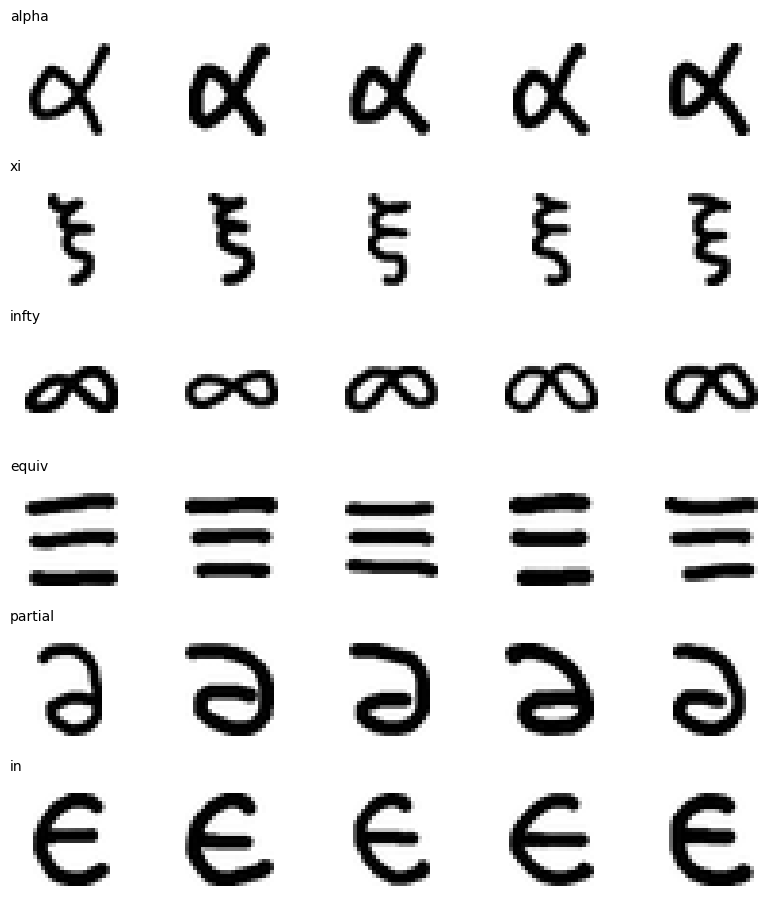

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 5, figsize=(8, 9), layout="constrained")
for class_index, symbol in enumerate(dataset.catalog["symbols"]):
    indices = np.flatnonzero(dataset.y == class_index)[:5]
    for column, ax in enumerate(axes[class_index]):
        ax.axis("off")
        if column < len(indices):
            ax.imshow(1 - dataset.X[indices[column], ..., 0], cmap="gray", vmin=0, vmax=1)
        if column == 0:
            ax.set_title(symbol["id"], loc="left", fontsize=10)
plt.show()


## 3. Separación según el origen

Se reservan **participantes completos**: P01 y P03 para entrenamiento (1,661), P04 para validación (750) y P02 para prueba (756). Los códigos se suministran explícitamente a la función original: la semilla no decide quién pasa a prueba. Se contrasta cada índice y `sample_id` con `split.json` y `model_info.json`; se exige cobertura completa, ausencia de solapamiento y seis clases presentes en cada partición.

P04 determina la selección de época y el paro temprano; P02 se usa para la evaluación final registrada y su comprobación actual. El protocolo supone un código estable por persona real; los archivos por sí solos no acreditan esa identidad. Cuatro participantes limitan la generalización a otras formas de escritura.


In [13]:
partitions = split_dataset(dataset, seed=SEED, validation_participants=['P04'], test_participants=['P02'])
groups = {name: set(dataset.participants[indices].tolist()) for name, indices in partitions.items()}
assert groups == EXPECTED_GROUPS
for name, indices in partitions.items():
    assert len(indices) == EXPECTED_COUNTS[name]
    assert indices.tolist() == split_saved[name]['indices'] == info['partitions'][name]['indices']
    assert [dataset.records[i]['sample_id'] for i in indices] == split_saved[name]['sample_ids'] == info['partitions'][name]['sample_ids']
    assert sorted(groups[name]) == split_saved[name]['participants'] == info['partitions'][name]['participants']
    counts_part = np.bincount(dataset.y[indices], minlength=6)
    assert (counts_part > 0).all()
    assert counts_part.tolist() == split_saved[name]['class_counts']
    print(name, '| participantes:', sorted(groups[name]), '| muestras:', len(indices), '| clases:', counts_part.tolist())
assert not groups['train'] & groups['validation']
assert not groups['train'] & groups['test']
assert not groups['validation'] & groups['test']
assert sorted(np.concatenate(list(partitions.values())).tolist()) == list(range(len(dataset.y)))
print('Particiones originales verificadas, sin solapamientos.')


train | participantes: ['P01', 'P03'] | muestras: 1661 | clases: [277, 276, 277, 277, 277, 277]
validation | participantes: ['P04'] | muestras: 750 | clases: [125, 125, 125, 125, 125, 125]
test | participantes: ['P02'] | muestras: 756 | clases: [126, 126, 126, 126, 126, 126]
Particiones originales verificadas, sin solapamientos.


## 4. Entrenar la CNN

Se conserva esta sección para explicar y recuperar el entrenamiento original. La arquitectura se importa de `src/model.py`: entrada **N×1×32×32** → Conv(1→16, 3×3, padding 1) → ReLU → MaxPool(2) → Conv(16→32, 3×3, padding 1) → ReLU → MaxPool(2) → 32×8×8 → Flatten(2048) → Linear(64) → ReLU → Dropout(0.25) → Linear(6). La salida son logits; softmax se usa para evaluación, no antes de entropía cruzada.

`src/training.py` usa Adam (`lr=0.001`, `weight_decay=0.0001`), batch 32, semilla 42, sin aumentos y CPU. Selecciona el estado con menor entropía cruzada de P04 (mejora mínima >1e-5); detiene tras siete épocas sin mejora, hasta 30. El historial registra **29 épocas** y la mejor es la **22**. La accuracy de entrenamiento se acumula durante actualizaciones y con dropout activo; la de validación se calcula al final de cada época en modo evaluación. Por eso sus curvas no representan exactamente el mismo procedimiento de medición.

La celda siguiente **lee** `history.json` y `model.pt`, verifica su compatibilidad y evalúa el checkpoint con `model.eval()` e `inference_mode()`. No ejecuta otra optimización. Para repetir el entrenamiento, utiliza `train_model` del repositorio con P04/P02 explícitos y un directorio nuevo que no exista; conserva el resultado original para comparación.


In [14]:
from torch.utils.data import DataLoader, TensorDataset
assert len(history) == info['epochs_run']
assert [row['epoch'] for row in history] == list(range(1, len(history)+1))
best_loss, best_epoch, waiting = float('inf'), 0, 0
for row in history:
    assert all(np.isfinite(row[key]) for key in ('train_loss','validation_loss','train_accuracy','validation_accuracy'))
    if row['validation_loss'] < best_loss - 0.00001:
        best_loss, best_epoch, waiting = row['validation_loss'], row['epoch'], 0
    else:
        waiting += 1
    print(f"Época {row['epoch']:02d} (historial): pérdida={row['train_loss']:.6f}; "
          f"validación={row['validation_loss']:.6f}; acc_val={row['validation_accuracy']:.4f}")
assert best_epoch == info['best_epoch'] == 22
assert waiting == PATIENCE and len(history) == 29
checkpoint = torch.load(OUTPUT/'model.pt', map_location='cpu', weights_only=True)
assert checkpoint['architecture'] == info['architecture'] == SymbolCNN.architecture
assert checkpoint['preprocessing'] == info['preprocessing'] == PREPROCESSING
assert catalog_signature(checkpoint['catalog']) == catalog_signature(dataset.catalog) == catalog_signature(info['catalog'])
model = SymbolCNN(6)
model.load_state_dict(checkpoint['state_dict'], strict=True)
assert all(torch.isfinite(value).all() for value in model.state_dict().values())
model.eval()
torch.set_num_threads(min(4, os.cpu_count() or 1))
images = torch.from_numpy(np.ascontiguousarray(dataset.X.transpose(0,3,1,2)))
labels = torch.from_numpy(dataset.y.copy())
def evaluation_loader(name):
    indices = partitions[name]
    return DataLoader(TensorDataset(images[indices], labels[indices]), batch_size=BATCH_SIZE, shuffle=False)
validation_loss, y_validation, probabilities_validation = evaluate(model, evaluation_loader('validation'))
best_row = history[best_epoch-1]
assert np.isclose(validation_loss, best_row['validation_loss'], rtol=1e-4, atol=1e-6)
assert np.isclose(np.mean(probabilities_validation.argmax(1)==y_validation), best_row['validation_accuracy'])
test_loss, y_test, probabilities_test = evaluate(model, evaluation_loader('test'))
metrics = classification_metrics(y_test, probabilities_test, dataset.catalog)
for key in ('top_1_accuracy','top_3_accuracy','macro_f1'):
    assert np.isclose(metrics[key], metrics_saved[key], rtol=0, atol=1e-12), key
assert metrics['confusion_matrix'] == metrics_saved['confusion_matrix']
assert np.isclose(test_loss, metrics_saved['loss'], rtol=1e-4, atol=1e-7)
print('Checkpoint verificado:', hashlib.sha256((OUTPUT/'model.pt').read_bytes()).hexdigest())
print('Parámetros:', sum(p.numel() for p in model.parameters()), '| Mejor época:', best_epoch)
print('Pérdida de prueba recomputada:', test_loss, '| original:', metrics_saved['loss'])
print('Historial recuperado y métricas reproducidas; no se entrenó ni se guardaron pesos.')


Época 01 (historial): pérdida=0.941786; validación=1.308947; acc_val=0.6707
Época 02 (historial): pérdida=0.148981; validación=0.895610; acc_val=0.8053
Época 03 (historial): pérdida=0.078142; validación=0.595007; acc_val=0.8413
Época 04 (historial): pérdida=0.045389; validación=0.537867; acc_val=0.8627
Época 05 (historial): pérdida=0.045768; validación=0.542731; acc_val=0.8720
Época 06 (historial): pérdida=0.026086; validación=0.518779; acc_val=0.8867
Época 07 (historial): pérdida=0.018210; validación=0.631853; acc_val=0.8653
Época 08 (historial): pérdida=0.010443; validación=0.861988; acc_val=0.8493
Época 09 (historial): pérdida=0.015862; validación=0.622795; acc_val=0.8893
Época 10 (historial): pérdida=0.008115; validación=0.584092; acc_val=0.8947
Época 11 (historial): pérdida=0.013464; validación=0.511870; acc_val=0.9093
Época 12 (historial): pérdida=0.011322; validación=0.502990; acc_val=0.9067
Época 13 (historial): pérdida=0.009245; validación=0.492238; acc_val=0.9120
Época 14 (hi

## 5. Resultados y errores

**Top-1** es la fracción de muestras cuya primera clase coincide con la etiqueta; **Top-3**, la fracción cuya etiqueta aparece entre las tres clases de mayor puntuación. La referencia aleatoria uniforme es 1/6 ≈16.67 % y 3/6 =50 %. Para cada clase, precisión=TP/(TP+FP), recall=TP/(TP+FN) y F1=2·precisión·recall/(precisión+recall). **F1 macro** promedia los seis F1 con el mismo peso.

La matriz usa **filas reales y columnas predichas**, en el orden del catálogo. Se verifican también las 756 filas de `test_predictions.csv` contra las etiquetas, IDs y tres candidatos recomputados. La evaluación cerrada de seis clases siempre calcula un ranking; la aplicación puede rechazar una entrada según confianza/margen. Por ello estas métricas no miden detección de símbolos desconocidos ni exactitud de la política de rechazo.


In [15]:
import csv
with (OUTPUT/'test_predictions.csv').open(newline='', encoding='utf-8') as stream:
    prediction_rows = list(csv.DictReader(stream))
assert len(prediction_rows) == len(partitions['test']) == 756
class_order = metrics['class_order']
ranking = np.argsort(-probabilities_test, axis=1, kind='stable')
for row, index, top in zip(prediction_rows, partitions['test'], ranking):
    record = dataset.records[index]
    assert row['sample_id'] == record['sample_id'] and row['participant_id'] == 'P02'
    assert row['real'] == record['class_id']
    assert [row[f'top_{k}'] for k in (1,2,3)] == [class_order[j] for j in top[:3]]
print('Muestras de prueba:', metrics['n_samples'])
print(f"Accuracy Top-1: {metrics['top_1_accuracy']:.4%}")
print(f"Accuracy Top-3: {metrics['top_3_accuracy']:.4%}")
print(f"F1 macro: {metrics['macro_f1']:.6f}")
print('Referencia aleatoria:', metrics['uniform_random_baseline'])
table = '| Clase | Precisión | Recall | F1 | Soporte |\n|---|---:|---:|---:|---:|\n'
for row in metrics['per_class']:
    table += f"| {row['id']} | {row['precision']:.4f} | {row['recall']:.4f} | {row['f1']:.4f} | {row['support']} |\n"
display(Markdown(table))
print('Orden de clases:', class_order)
print('Matriz de confusión (real × predicha):\n', np.asarray(metrics['confusion_matrix']))
print('756 predicciones originales contrastadas con el checkpoint.')


Muestras de prueba: 756
Accuracy Top-1: 100.0000%
Accuracy Top-3: 100.0000%
F1 macro: 1.000000
Referencia aleatoria: {'top_1_accuracy': 0.16666666666666666, 'top_3_accuracy': 0.5}


| Clase | Precisión | Recall | F1 | Soporte |
|---|---:|---:|---:|---:|
| alpha | 1.0000 | 1.0000 | 1.0000 | 126 |
| xi | 1.0000 | 1.0000 | 1.0000 | 126 |
| infty | 1.0000 | 1.0000 | 1.0000 | 126 |
| equiv | 1.0000 | 1.0000 | 1.0000 | 126 |
| partial | 1.0000 | 1.0000 | 1.0000 | 126 |
| in | 1.0000 | 1.0000 | 1.0000 | 126 |


Orden de clases: ['alpha', 'xi', 'infty', 'equiv', 'partial', 'in']
Matriz de confusión (real × predicha):
 [[126   0   0   0   0   0]
 [  0 126   0   0   0   0]
 [  0   0 126   0   0   0]
 [  0   0   0 126   0   0]
 [  0   0   0   0 126   0]
 [  0   0   0   0   0 126]]
756 predicciones originales contrastadas con el checkpoint.


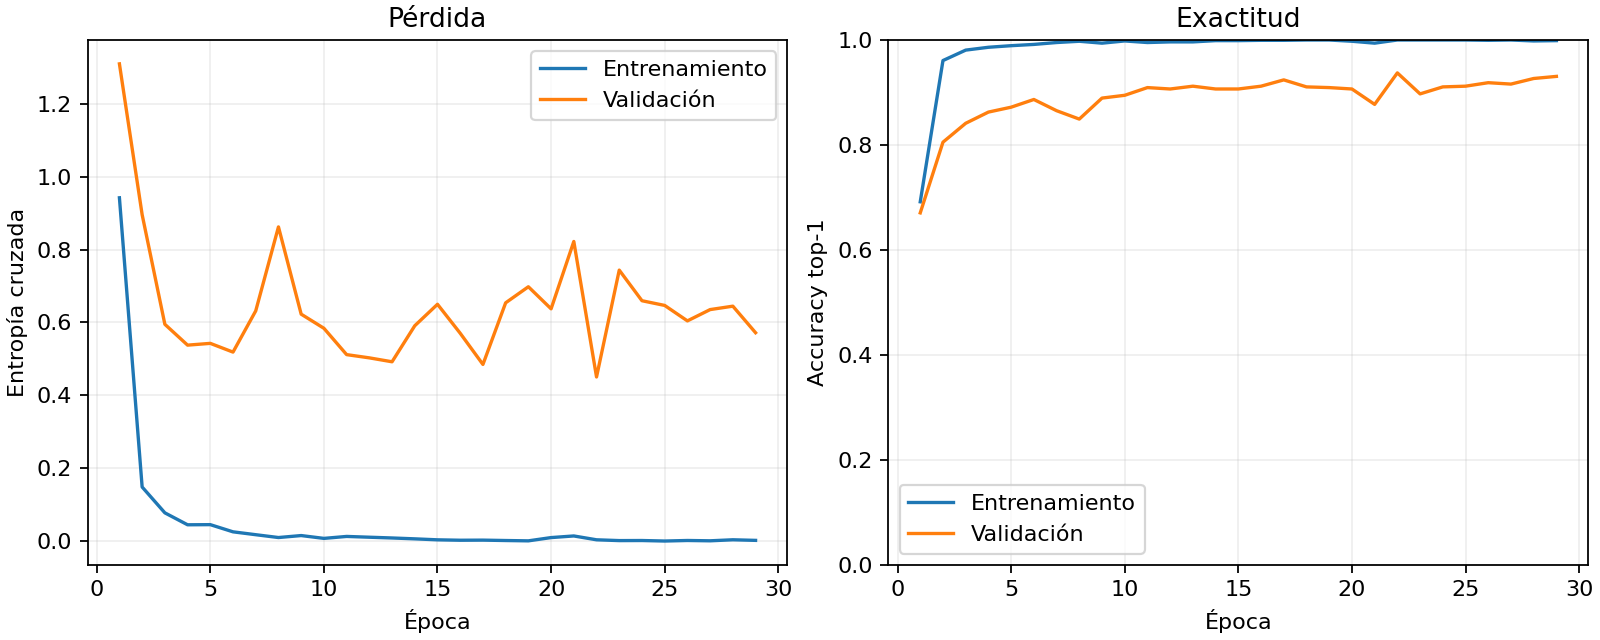

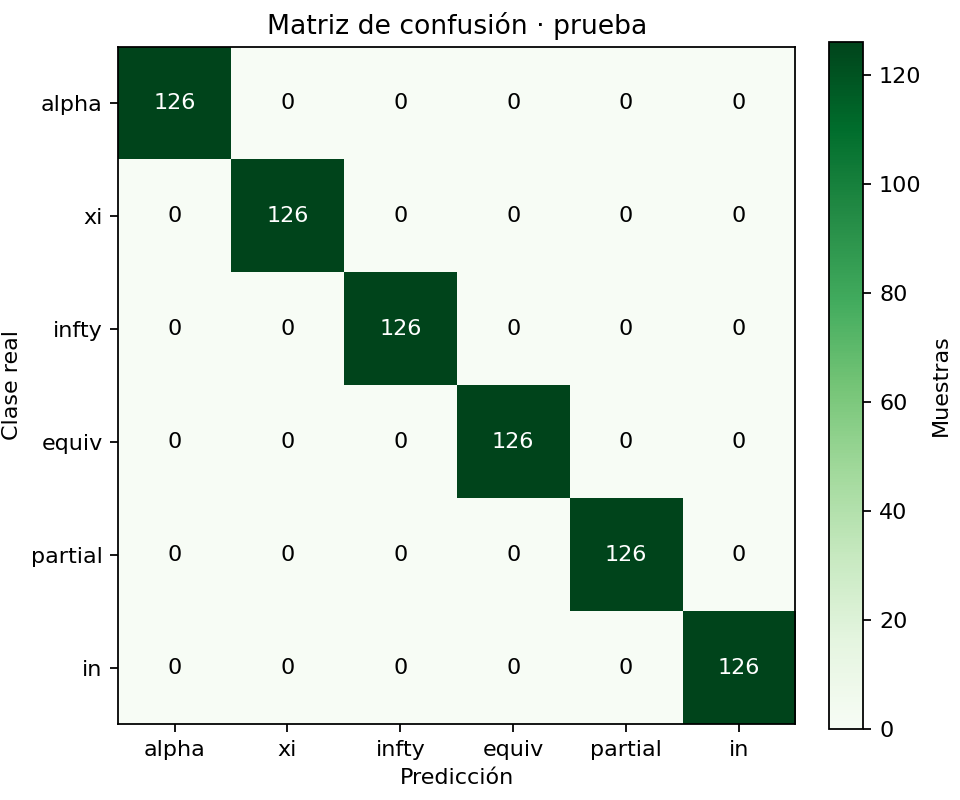

Curvas: 29 épocas del historial original; matriz: evaluación del checkpoint en P02.


In [16]:
# Figuras regeneradas desde history.json y las métricas comprobadas; no se escriben en models/.
import matplotlib.pyplot as plt
from src.training import save_plots
with tempfile.TemporaryDirectory(prefix='pc2-figuras-') as temporary:
    figures = Path(temporary)
    save_plots(history, metrics, dataset.catalog, figures)
    display(NotebookImage(data=(figures/'learning_curves.png').read_bytes()))
    display(NotebookImage(data=(figures/'confusion_matrix.png').read_bytes()))
print('Curvas: 29 épocas del historial original; matriz: evaluación del checkpoint en P02.')


## 6. Comprobar la integración con Flask

Se toma un PNG original de P02 y se consulta `/predict` con el cliente de pruebas de Flask. Se usa un almacén temporal para que la comprobación no añada datos al proyecto. Se valida la compatibilidad del modelo y que la ruta no guarde consultas.

La versión real de `PredictionService` devuelve tres candidatos **si reconoce** la entrada; puede devolver cero si la rechaza. La prueba respeta ambas respuestas y las contrasta con la inferencia directa. No obliga artificialmente a aceptar cualquier trazo ni publica un servidor. Esta comprobación de integración no equivale a una nueva evaluación manual con mouse.


In [17]:
from main import create_app
from src.prediction import PredictionService
import base64
index = int(partitions['test'][0])
record = dataset.records[index]
png = (raw_directory/record['path']).read_bytes()
with Image.open(raw_directory/record['path']) as image:
    processed = preprocess_image(image)
with tempfile.TemporaryDirectory(prefix='pc2-flask-') as temporary:
    app_test = create_app(Path(temporary)/'queries', OUTPUT)
    client = app_test.test_client()
    assert client.get('/api/model').json['ready']
    before = client.get('/api/counts').json['counts']
    response = client.post('/predict', json={'image':'data:image/png;base64,'+base64.b64encode(png).decode('ascii')})
    assert response.status_code == 200, response.json
    result = response.json
    assert len(result['candidates']) == (3 if result['recognized'] else 0)
    assert client.get('/api/counts').json['counts'] == before
    expected = app_test.extensions['prediction_service'].predict(processed)
    assert result['recognized'] == expected['recognized']
    assert result['candidates'] == expected['candidates']
    assert {c['latex'] for c in result['candidates']} <= {s['latex'] for s in dataset.catalog['symbols']}
    print('Clase real:', record['class_id'], '| Reconocido:', result['recognized'])
    for candidate in result['candidates']:
        print(candidate['unicode'], candidate['name'], candidate['latex'], f"score={candidate['score']:.6f}")
    print('Rechazo:', result['rejection_method'], '| Estado:', result['calibration_status'])
assert protected_hashes() == PROTECTED_BEFORE, 'Cambió un archivo protegido.'
print('Integración Flask verificada. Datos y modelos originales: hashes SHA-256 sin cambios.')


Clase real: alpha | Reconocido: True
α Alfa minúscula \alpha score=1.000000
∞ Infinito \infty score=0.000000
ξ Xi minúscula \xi score=0.000000
Rechazo: softmax_confidence_margin | Estado: uncalibrated
Integración Flask verificada. Datos y modelos originales: hashes SHA-256 sin cambios.


## Piloto manual con mouse — 30 consultas

**Antecedente conservado del notebook original, no reevaluado aquí.** No existe en este bloque una vinculación verificable con el hash del checkpoint actual; sus cifras no se combinan con la evaluación de P02 ni se atribuyen al modelo propio actual.

Este bloque registra los conteos agregados reportados por Alan después del entrenamiento local. No ejecuta ni simula nuevas consultas; no contiene predicciones individuales ni PNG. Se reportan un participante, mouse y cinco consultas por clase.

| Clase | Símbolo | Consultas | Top-1 | Top-3 |
|---|:---:|---:|---:|---:|
| alpha | α | 5 | 3/5 | 5/5 |
| xi | ξ | 5 | 3/5 | 4/5 |
| infty | ∞ | 5 | 3/5 | 5/5 |
| equiv | ≡ | 5 | 3/5 | 5/5 |
| partial | ∂ | 5 | 3/5 | 5/5 |
| in | ∈ | 5 | 4/5 | 5/5 |
| **Total** | | **30** | **19/30 — 63,33 %** | **29/30 — 96,67 %** |

Top-1: **19/30 = 63,33 %**. Top-3: **29/30 = 96,67 %**. Mostrar tres alternativas recuperó **10 de los 11 errores** de la primera sugerencia. Es una prueba pequeña; no mide generalización a múltiples personas ni permite calcular F1 o una matriz de confusión sin las clases predichas por consulta.



